# Customer Churn Prediction and Retention Analysis

**Objective:** build a reproducible churn-risk pipeline on the public IBM Telco
Customer Churn sample, compare models using train-only cross-validation, evaluate
the selected model once on a held-out test set, and translate results into retention
actions.

The notebook is designed to run both on **Kaggle** and from this GitHub repository.
It uses a fixed random seed and keeps preprocessing inside each model pipeline to
prevent train/test leakage.

## 1. Imports and configuration

No internet access is needed after the dataset has been attached to the Kaggle
notebook or placed in `data/raw/` locally.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    precision_score, recall_score, roc_auc_score, RocCurveDisplay
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## 2. Locate and load the dataset

In [2]:
LOCAL_PATH = Path("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
candidates = [LOCAL_PATH]
kaggle_root = Path("/kaggle/input")
if kaggle_root.exists():
    candidates.extend(kaggle_root.rglob("*.csv"))

data_path = next(
    (path for path in candidates if path.exists() and "churn" in path.name.lower()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Attach the Kaggle 'Telco Customer Churn' dataset or place the CSV at "
        f"{LOCAL_PATH}."
    )

df = pd.read_csv(data_path)
print(f"Loaded: {data_path}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded: data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data audit and cleaning

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_before_cleaning": df.isna().sum(),
    "unique_values": df.nunique(),
})
display(audit)
print("Duplicate rows:", df.duplicated().sum())
print("Blank TotalCharges values:", df["TotalCharges"].astype(str).str.strip().eq("").sum())

,dtype,missing_before_cleaning,unique_values
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Duplicate rows: 0
Blank TotalCharges values: 11


In [4]:
df = df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Rows:", len(df))
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
print("Overall churn rate: {:.1%}".format(df["Churn"].mean()))

Rows: 7043
Missing TotalCharges after conversion: 11
Overall churn rate: 26.5%


The 11 blank `TotalCharges` values correspond to customers with zero tenure.
They are not filled globally here: median imputation is learned inside each
cross-validation training fold, which avoids leakage.

## 4. Exploratory data analysis

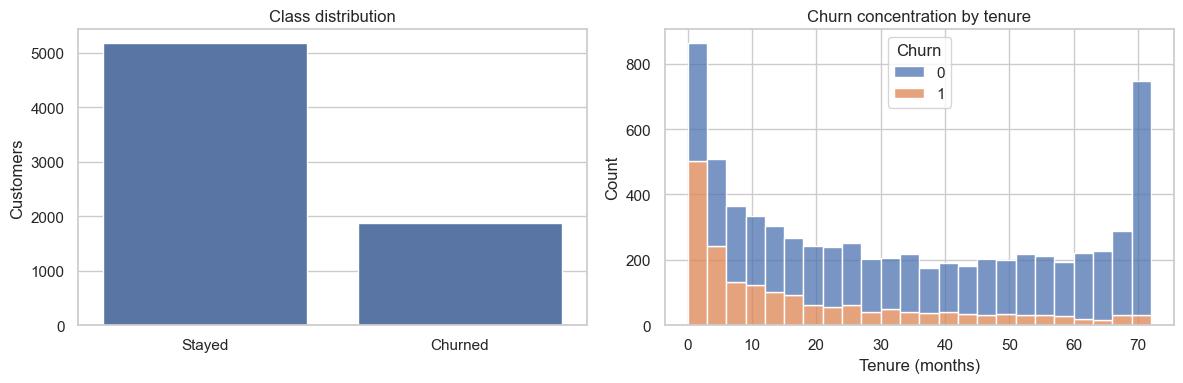

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
churn_counts = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts()
sns.barplot(x=churn_counts.index, y=churn_counts.values, ax=axes[0])
axes[0].set(title="Class distribution", ylabel="Customers", xlabel="")

sns.histplot(data=df, x="tenure", hue="Churn", bins=24, multiple="stack", ax=axes[1])
axes[1].set(title="Churn concentration by tenure", xlabel="Tenure (months)")
plt.tight_layout()
plt.show()

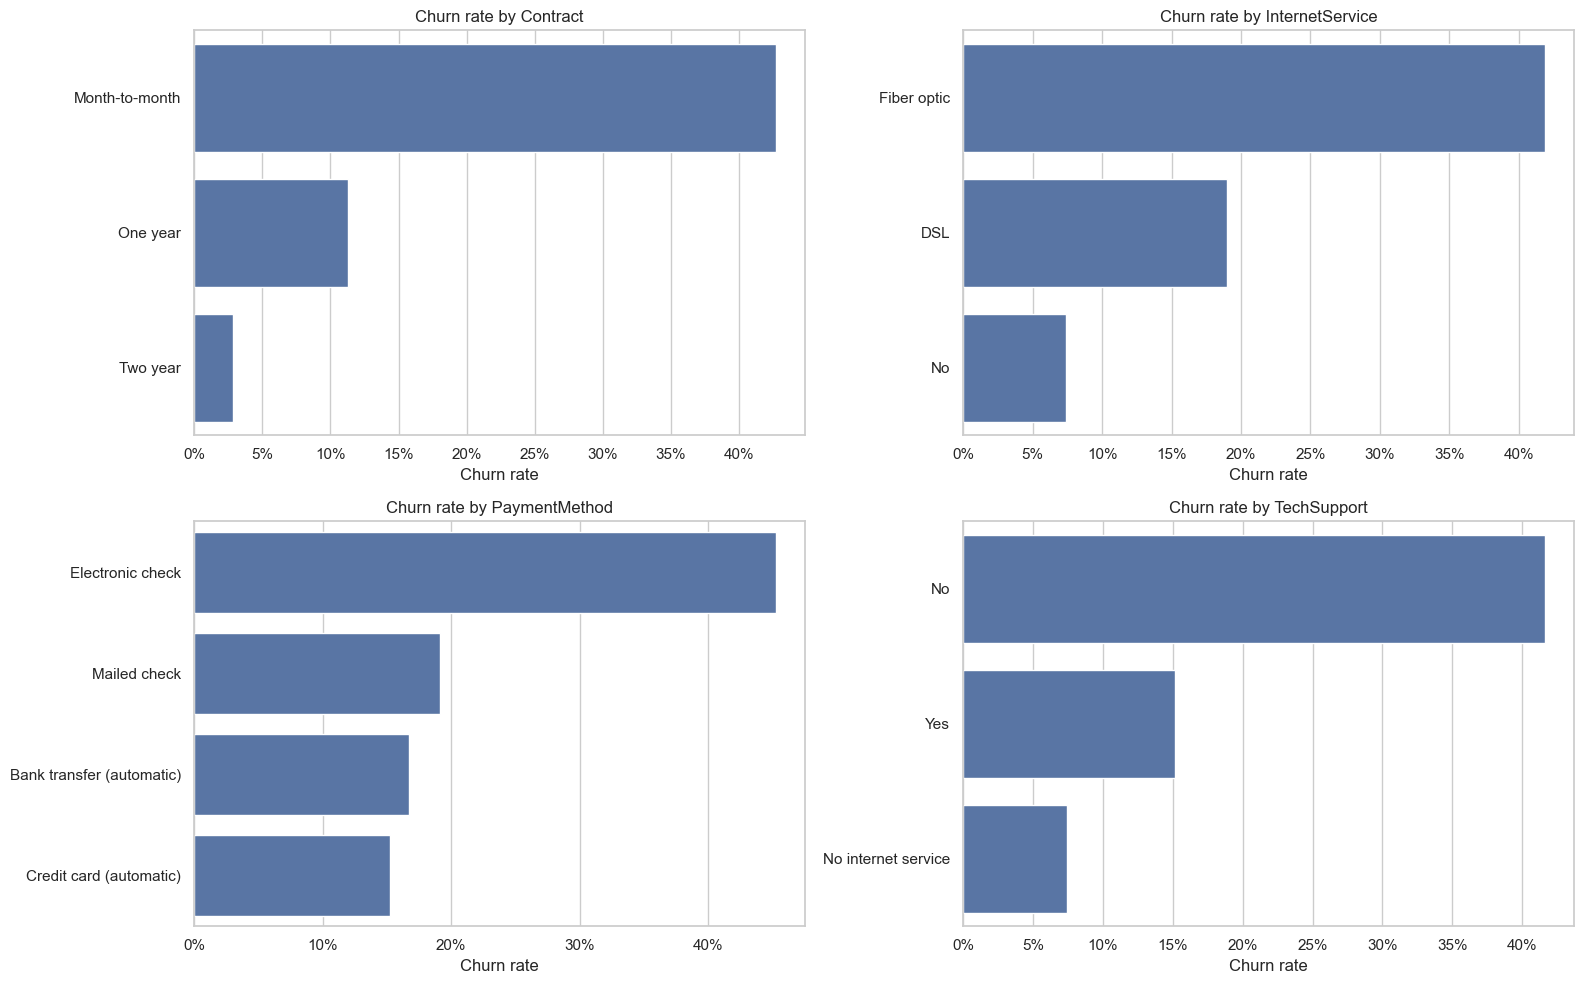

In [6]:
drivers = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for column, ax in zip(drivers, axes.ravel()):
    rates = (
        df.groupby(column, observed=True)["Churn"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )
    sns.barplot(data=rates, y=column, x="mean", ax=ax)
    ax.set(title=f"Churn rate by {column}", xlabel="Churn rate", ylabel="")
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.tight_layout()
plt.show()

In [7]:
segment_summary = []
for column in drivers:
    summary = (
        df.groupby(column, observed=True)["Churn"]
        .agg(customers="size", churn_rate="mean")
        .reset_index()
        .rename(columns={column: "segment"})
    )
    summary.insert(0, "feature", column)
    segment_summary.append(summary)
segment_summary = pd.concat(segment_summary, ignore_index=True)
top_segments = segment_summary.sort_values("churn_rate", ascending=False).head(10).copy()
top_segments["churn_rate"] = top_segments["churn_rate"].map(lambda value: f"{value:.1%}")
display(top_segments)

,feature,segment,customers,churn_rate
8,PaymentMethod,Electronic check,2365,45.3%
0,Contract,Month-to-month,3875,42.7%
4,InternetService,Fiber optic,3096,41.9%
10,TechSupport,No,3473,41.6%
9,PaymentMethod,Mailed check,1612,19.1%
3,InternetService,DSL,2421,19.0%
6,PaymentMethod,Bank transfer (automatic),1544,16.7%
7,PaymentMethod,Credit card (automatic),1522,15.2%
12,TechSupport,Yes,2044,15.2%
1,Contract,One year,1473,11.3%


## 5. Leakage-safe preprocessing and train/test split

In [8]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].astype(int)
customer_ids = df["customerID"]

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, customer_ids,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print(f"Training rows: {len(X_train):,}")
print(f"Held-out test rows: {len(X_test):,}")

Training rows: 5,634
Held-out test rows: 1,409


## 6. Model comparison

Model selection uses only the training partition with stratified 5-fold
cross-validation and ROC-AUC. The held-out test set remains untouched until a
model has been selected.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", solver="liblinear",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=4, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, pipelines = [], {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    results.append({
        "model": name,
        "cv_roc_auc_mean": scores.mean(),
        "cv_roc_auc_std": scores.std(),
    })
    pipelines[name] = pipeline

comparison = pd.DataFrame(results).sort_values("cv_roc_auc_mean", ascending=False)
display(comparison.round(3))

,model,cv_roc_auc_mean,cv_roc_auc_std
0,Logistic Regression,0.846,0.012
1,Random Forest,0.843,0.008


## 7. Final held-out evaluation

In [10]:
best_name = comparison.iloc[0]["model"]
best_model = pipelines[best_name].fit(X_train, y_train)
test_probability = best_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.50).astype(int)

metrics = {
    "dataset_rows": len(df),
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "positive_rate": y.mean(),
    "selected_model": best_name,
    "selection_method": "Highest mean ROC-AUC in stratified 5-fold CV on training data",
    "test_roc_auc": roc_auc_score(y_test, test_probability),
    "test_accuracy": accuracy_score(y_test, test_prediction),
    "test_precision": precision_score(y_test, test_prediction),
    "test_recall": recall_score(y_test, test_prediction),
    "random_state": RANDOM_STATE,
}
pd.Series(metrics).to_frame("held_out_test_result")

,held_out_test_result
dataset_rows,7043
train_rows,5634
test_rows,1409
positive_rate,0.26537
selected_model,Logistic Regression
selection_method,Highest mean ROC-AUC in stratified 5-fold CV o...
test_roc_auc,0.841466
test_accuracy,0.738112
test_precision,0.504303
test_recall,0.783422


              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



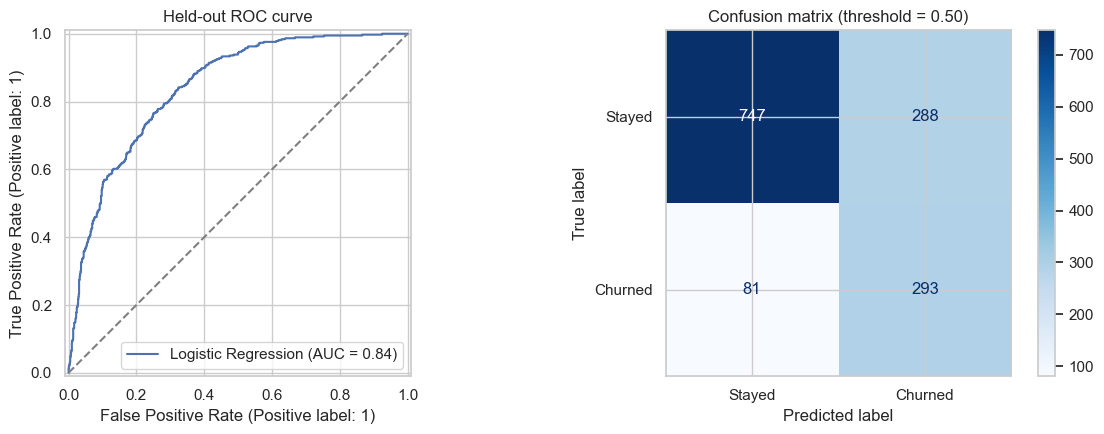

In [11]:
print(classification_report(y_test, test_prediction, target_names=["Stayed", "Churned"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(
    y_test, test_probability, name=best_name, ax=axes[0]
)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Held-out ROC curve")
ConfusionMatrixDisplay.from_predictions(
    y_test, test_prediction, display_labels=["Stayed", "Churned"],
    cmap="Blues", ax=axes[1]
)
axes[1].set_title("Confusion matrix (threshold = 0.50)")
plt.tight_layout()
plt.show()

## 8. Explain the strongest model signals

In [12]:
transformed_names = best_model.named_steps["preprocess"].get_feature_names_out()
estimator = best_model.named_steps["model"]

if hasattr(estimator, "coef_"):
    importance = pd.Series(estimator.coef_[0], index=transformed_names)
    signal_table = pd.concat([
        importance.nlargest(10).rename("increases_churn_risk"),
        importance.nsmallest(10).sort_values().rename("reduces_churn_risk")
    ], axis=1)
    display(signal_table)
else:
    importance = pd.Series(estimator.feature_importances_, index=transformed_names)
    display(importance.nlargest(15).to_frame("feature_importance"))

,increases_churn_risk,reduces_churn_risk
categorical__InternetService_Fiber optic,0.702076,NaN
categorical__Contract_Month-to-month,0.652960,NaN
numeric__TotalCharges,0.473477,NaN
categorical__StreamingMovies_Yes,0.270116,NaN
categorical__StreamingTV_Yes,0.256830,NaN
categorical__PaymentMethod_Electronic check,0.235640,NaN
categorical__OnlineSecurity_No,0.193157,NaN
categorical__TechSupport_No,0.159324,NaN
categorical__MultipleLines_Yes,0.128587,NaN
categorical__DeviceProtection_Yes,0.068330,NaN


## 9. Create a customer risk list for a retention team

In [13]:
risk_scores = pd.DataFrame({
    "customerID": ids_test.reset_index(drop=True),
    "actual_churn": y_test.reset_index(drop=True),
    "churn_probability": test_probability,
    "predicted_churn": test_prediction,
})
risk_scores["risk_band"] = pd.cut(
    risk_scores["churn_probability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"],
)
risk_scores = risk_scores.sort_values("churn_probability", ascending=False)
display(risk_scores.head(15))

,customerID,actual_churn,churn_probability,predicted_churn,risk_band
1090,5178-LMXOP,1,0.938028,1,High
1221,0295-PPHDO,1,0.926827,1,High
1175,6861-XWTWQ,1,0.926051,1,High
1164,8884-ADFVN,1,0.922344,1,High
1109,1069-XAIEM,1,0.920543,1,High
889,2545-EBUPK,0,0.920316,1,High
1138,1400-MMYXY,1,0.920178,1,High
647,6023-YEBUP,1,0.919468,1,High
627,9057-SIHCH,1,0.919033,1,High
995,8161-QYMTT,0,0.918077,1,High


## 10. Business recommendations

- Prioritize high-risk month-to-month customers for proactive outreach.
- Test annual-contract incentives instead of offering blanket discounts.
- Investigate the high churn observed in fiber-optic and electronic-check segments.
- Bundle technical support and online security trials for at-risk accounts.
- Measure campaign lift with a randomized holdout group; model score alone does not
  prove that an offer will prevent churn.

**Limitations:** this is a small, fictional sample with no timestamps, usage history,
acquisition cost, retention-offer outcome, or causal treatment label. Results are a
portfolio demonstration and should not be represented as production deployment.

## 11. Save reproducible outputs

In [14]:
output_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("artifacts")
output_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, output_dir / "churn_model.joblib")
risk_scores.to_csv(output_dir / "customer_risk_scores.csv", index=False)
comparison.to_csv(output_dir / "model_comparison.csv", index=False)
with (output_dir / "metrics.json").open("w") as handle:
    json.dump({key: (float(value) if isinstance(value, (float, np.floating)) else value)
               for key, value in metrics.items()}, handle, indent=2)
print(f"Saved model and reports to: {output_dir.resolve()}")

Saved model and reports to: C:\Users\PLEXTEK\Documents\ChatGPT\customer churn prediction\artifacts
